# code_060 · Compact representations and learned features

**Book:** section 12.4. A self-contained feature-engineering laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_12_GUIDE.md), [run evidence](../CHAPTER_12_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_060).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose representation assumptions, fitting boundaries and operational constraints without field-validity, causal or universal feature-selection claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1260;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1260


<a id="signals"></a>
## Compare representations of the same signal windows

Generate 550 independent acceleration windows, 64 samples at 64 Hz. Each is A*sin(2*pi*4t+phase1)+B*sin(2*pi*9t+phase2)+noise .05 mm/s², with independent phases and amplitudes A in [.4,1.8], B in [.2,1.2]. Target y=.2+1.5*A**2+.3*B**2+noise .1 is a dimensionless generated response index, not a validated damage score. Train/development/final counts 300/100/150. Known 4/9-Hz mean-square band contributions express a phase-invariance hypothesis; fixed eight-component PCA and an eight-unit tanh autoencoder fit training windows only, without target labels. A raw 64-column baseline is retained. Each representation feeds StandardScaler/Ridge alpha=1, fitted on training targets only. No final result selects a dimension or representation.


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
N=550;T=64;t=np.arange(T)/64;A=rng.uniform(.4,1.8,N);B=rng.uniform(.2,1.2,N);ph1=rng.uniform(0,2*np.pi,N);ph2=rng.uniform(0,2*np.pi,N)
X=A[:,None]*np.sin(2*np.pi*4*t+ph1[:,None])+B[:,None]*np.sin(2*np.pi*9*t+ph2[:,None])+rng.normal(0,.05,(N,T));y=.2+1.5*A*A+.3*B*B+rng.normal(0,.1,N);tr=np.arange(300);dv=np.arange(300,400);te=np.arange(400,550)
assert X.shape==(550,64) and not set(tr)&set(te)
scale=StandardScaler().fit(X[tr]);Z=scale.transform(X);pca=PCA(n_components=8,svd_solver='full').fit(Z[tr]);lowrank=pca.transform(Z)
P=np.abs(np.fft.rfft(X,axis=1))**2/T**2;spectral=2*P[:,[4,9]]
# One-sided mean-square at the known bins, no learned fit on final windows.
assert spectral.shape==(550,2) and (spectral>=0).all()


<a id="encoder"></a>
## Train an explicit nonlinear bottleneck

The autoencoder is H=tanh(ZW+b), reconstruction=HV+c with eight hidden units and linear output. Minimize mean squared reconstruction error over training entries plus 1e-4 times squared weight norms. Full-batch gradient descent uses 2,000 predeclared updates, learning rate .1, fixed seed initialization and no early stopping. The central-difference check audits one encoder-weight derivative before training. The fixed budget is not a global-optimum or convergence certificate; the loss history remains visible. The learned code is not a pretrained foundation embedding or an end-to-end supervised feature extractor.


In [3]:
Ztr=Z[tr];h=8;reg=1e-4;W=rng.normal(0,.15,(T,h));b=np.zeros(h);V=rng.normal(0,.15,(h,T));c=np.zeros(T)
def loss_grad(W,b,V,c):
 H=np.tanh(Ztr@W+b);R=H@V+c-Ztr;loss=np.mean(R*R)+reg*(np.sum(W*W)+np.sum(V*V));D=2*R/R.size;gV=H.T@D+2*reg*V;gc=D.sum(axis=0);Q=(D@V.T)*(1-H*H);gW=Ztr.T@Q+2*reg*W;gb=Q.sum(axis=0);return float(loss),(gW,gb,gV,gc)
base,g=loss_grad(W,b,V,c);eps=1e-6;Wp=W.copy();Wm=W.copy();Wp[0,0]+=eps;Wm[0,0]-=eps;numeric=(loss_grad(Wp,b,V,c)[0]-loss_grad(Wm,b,V,c)[0])/(2*eps);np.testing.assert_allclose(numeric,g[0][0,0],rtol=1e-5,atol=1e-8)
history=[]
for iteration in range(2000):
 loss,grads=loss_grad(W,b,V,c)
 if iteration%100==0:history.append([iteration,loss])
 W-=.1*grads[0];b-=.1*grads[1];V-=.1*grads[2];c-=.1*grads[3]
final_loss,_=loss_grad(W,b,V,c);history.append([2000,final_loss]);assert final_loss<base
code=np.tanh(Z@W+b);reconstructed=code@V+c
RESULTS['autoencoder_training_objective']={'initial':base,'final':final_loss,'updates':2000,'hidden_units':8,'gradient_check_passed':True}


<a id="downstream"></a>
## Assess the downstream objective independently of reconstruction

Reconstruction rewards retaining high-variance waveform structure. The target depends on squared amplitudes and is phase-invariant, so a linear readout of raw/PCA/code coordinates may miss that function even when reconstruction is good. This comparison includes representation plus a fixed linear readout; it does not rank all encoders or readout families. Representation learning with target loss would be a different end-to-end procedure and must keep its supervised fitting boundary. Transfer to new frequencies or acquisition hardware is not demonstrated here.


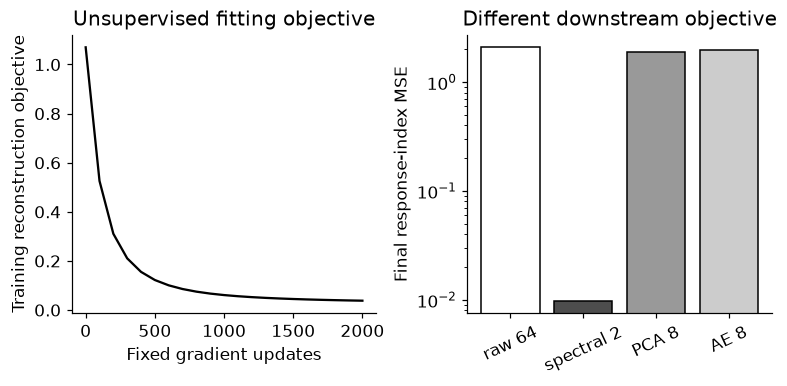

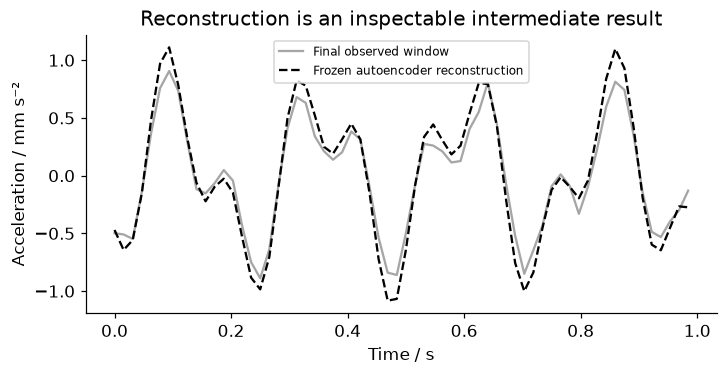

In [4]:
representations={'raw_64':Z,'spectral_2':spectral,'PCA_8':lowrank,'autoencoder_8':code};metrics={}
for name,R in representations.items():
 fit=make_pipeline(StandardScaler(),Ridge(alpha=1)).fit(R[tr],y[tr]);pred=fit.predict(R[te]);assert np.isfinite(pred).all()
 metrics[name]={'development_MSE':float(mean_squared_error(y[dv],fit.predict(R[dv]))),'final_MSE':float(mean_squared_error(y[te],pred)),'columns':R.shape[1]}
RESULTS['downstream_metrics']=metrics;RESULTS['final_standardized_reconstruction_MSE']={'PCA_8':float(mean_squared_error(Z[te],pca.inverse_transform(lowrank[te]))),'autoencoder_8':float(mean_squared_error(Z[te],reconstructed[te]))}
fig,axes=plt.subplots(1,2,figsize=(7,3.4));hist=np.array(history);axes[0].plot(hist[:,0],hist[:,1],color='black');axes[0].set(xlabel='Fixed gradient updates',ylabel='Training reconstruction objective',title='Unsupervised fitting objective');axes[1].bar(np.arange(4),[metrics[k]['final_MSE'] for k in metrics],color=['white','.3','.6','.8'],edgecolor='black');axes[1].set(xticks=np.arange(4),xticklabels=['raw 64','spectral 2','PCA 8','AE 8'],ylabel='Final response-index MSE',yscale='log',title='Different downstream objective');axes[1].tick_params(axis='x',labelrotation=25);plt.show()
fig,ax=plt.subplots(figsize=(6.5,3.3));i=te[0];ax.plot(t,X[i],color='.65',label='Final observed window');ax.plot(t,scale.inverse_transform(reconstructed[i:i+1])[0],color='black',ls='--',label='Frozen autoencoder reconstruction');ax.set(xlabel='Time / s',ylabel='Acceleration / mm s⁻²',title='Reconstruction is an inspectable intermediate result');ax.legend(fontsize=8);plt.show()


In [5]:
summary={'example_id':'code_060','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['hand-built spectral and low-rank features', 'self-contained nonlinear autoencoder', 'training-only representation fitting', 'reconstruction versus downstream performance'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["hand-built spectral and low-rank features", "self-contained nonlinear autoencoder", "training-only representation fitting", "reconstruction versus downstream performance"], "elapsed_seconds": 0.477, "example_id": "code_060", "hardware": "Darwin arm64 CPU", "results": {"autoencoder_training_objective": {"final": 0.03796629886770185, "gradient_check_passed": true, "hidden_units": 8, "initial": 1.0699369541210484, "updates": 2000}, "downstream_metrics": {"PCA_8": {"columns": 8, "development_MSE": 1.8328225142968833, "final_MSE": 1.8955269441641607}, "autoencoder_8": {"columns": 8, "development_MSE": 1.8326634893644824, "final_MSE": 1.9655393418341154}, "raw_64": {"columns": 64, "development_MSE": 1.8897926466318047, "final_MSE": 2.086286224061799}, "spectral_2": {"columns": 2, "development_MSE": 0.009940248027750303, "final_MSE": 0.009810792690620657}}, "final_standardized_reconstruction_MSE": {"PCA_8": 0.0023706296720713794, "autoencoder